In [2]:
import os
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
BASE_DIR = '/content/drive/MyDrive/PCVK'
PCVK_DIR = '/content/drive/MyDrive/PCVK'
IMAGE_DIR = os.path.join(PCVK_DIR, 'Images')
OBJECT_DIR = os.path.join(IMAGE_DIR, 'Object_Detection')
FACE_DIR = os.path.join(IMAGE_DIR, 'facedet')
HAAR_DIR = os.path.join(IMAGE_DIR, 'haarcascades')

In [16]:
print('PCVK:', os.path.isdir(PCVK_DIR))
print('Images:', os.path.isdir(IMAGE_DIR))
print('Object_Detection:', os.path.isdir(OBJECT_DIR))
print('facedet:', os.path.isdir(FACE_DIR))
print('haarcascades:', os.path.isdir(HAAR_DIR))

print('\nIsi Object_Detection:')
if os.path.isdir(OBJECT_DIR):
    print('\n'.join(sorted(os.listdir(OBJECT_DIR))))
else:
    print('Folder Object_Detection tidak ditemukan.')

print('\nIsi facedet:')
if os.path.isdir(FACE_DIR):
    print('\n'.join(sorted(os.listdir(FACE_DIR))))
else:
    print('Folder facedet tidak ditemukan.')

PCVK: True
Images: True
Object_Detection: True
facedet: True
haarcascades: True

Isi Object_Detection:
animal-template.jpg
animal.jpg
bahrain-template.jpg
bahrain.jpg
car-park.jpg
cat-and-rabbit.jpg
cat-template.jpg
cat2_templatejpg.jpg
cats_and_bunnies.jpg
chess-board.jpg
laptop.jpg
parking-lot-cars.jpg
sudoku.jpg

Isi facedet:
jokowi.jpg
kartini.jpg
kucing.jpg
many_cereals.jpg
mask.png
mjordan.jpg
reeses_puffs.png
solvayconf.jpg


In [17]:
# Fungsi bantu untuk mencari gambar pada folder yang benar
def image_path(filename, folder=IMAGE_DIR):
    path = os.path.join(folder, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f'File tidak ditemukan: {path}. Periksa nama file dan foldernya.'
        )
    return path

def find_image(filename, folders):
    # Mencari nama file persis di daftar folder yang ditentukan
    for folder in folders:
        if os.path.isdir(folder):
            candidate = os.path.join(folder, filename)
            if os.path.isfile(candidate):
                return candidate

    # Jika nama lengkap sedikit berbeda, cari nama yang diawali nama dasar file
    stem = os.path.splitext(filename)[0].lower()
    for folder in folders:
        if os.path.isdir(folder):
            for item in os.listdir(folder):
                item_stem = os.path.splitext(item)[0].lower()
                if item_stem == stem or item_stem.startswith(stem):
                    candidate = os.path.join(folder, item)
                    if os.path.isfile(candidate):
                        return candidate

    raise FileNotFoundError(
        f'{filename} tidak ditemukan. Folder yang diperiksa: {folders}'
    )

def show_image(image, title='', cmap=None, figsize=(8, 6)):
    plt.figure(figsize=figsize)
    if image.ndim == 2:
        plt.imshow(image, cmap=cmap or 'gray')
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

Soal 2 – Implementasi 6 metode Template Matching
Implementasikan 6 metode template matching pada OpenCV menggunakan cats_and_bunnies.jpg sebagai citra masukan dan cat2_template.jpg sebagai citra template.

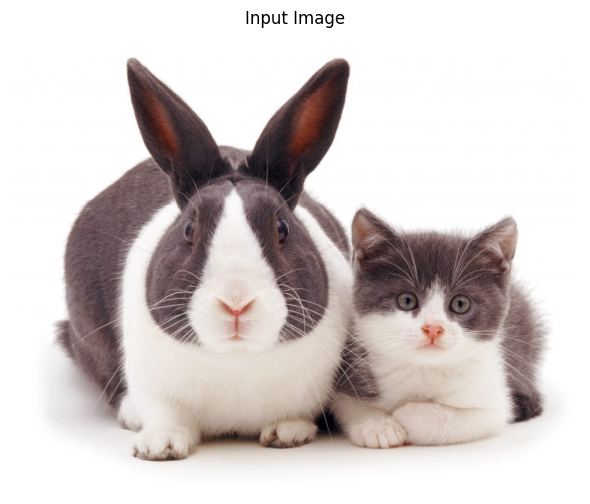

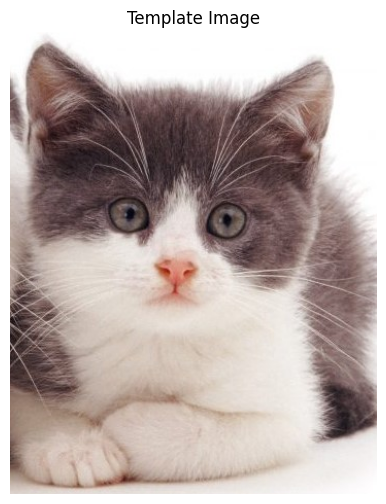

In [18]:
# Membaca citra masukan dan citra template
source = cv2.imread(image_path('cats_and_bunnies.jpg', OBJECT_DIR))

# Nama file mengikuti penulisan pada modul; nama alternatif disediakan sebagai fallback.
template_file = find_image('cat2_templatejpg.jpg', [OBJECT_DIR])
template = cv2.imread(template_file)

if source is None or template is None:
    raise ValueError('Gambar tidak dapat dibaca. Periksa format dan nama file.')

source_gray = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
template_gray = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)

h, w = template_gray.shape
show_image(source, 'Input Image')
show_image(template, 'Template Image')

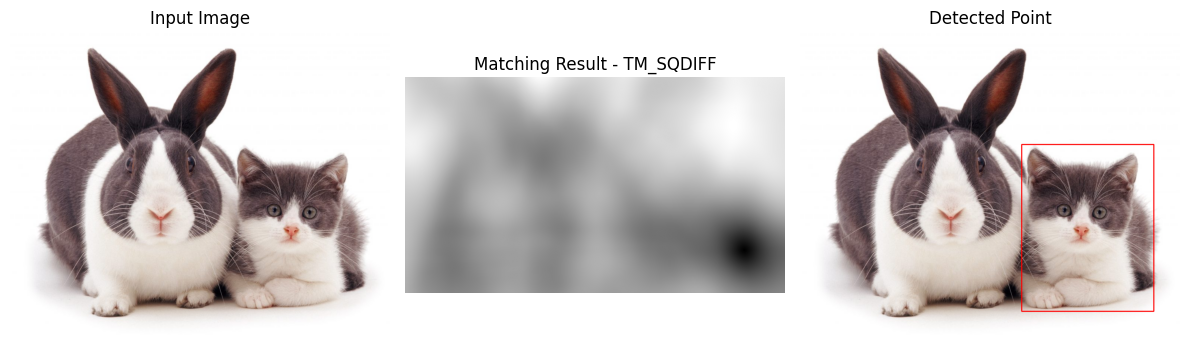

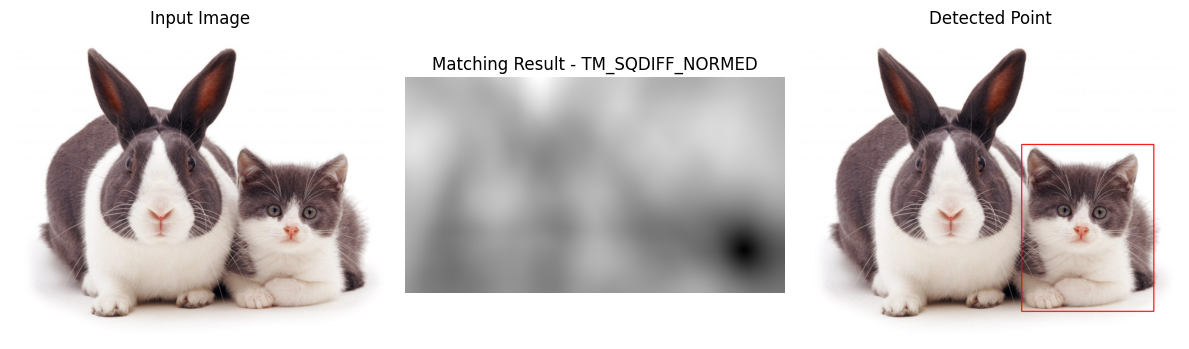

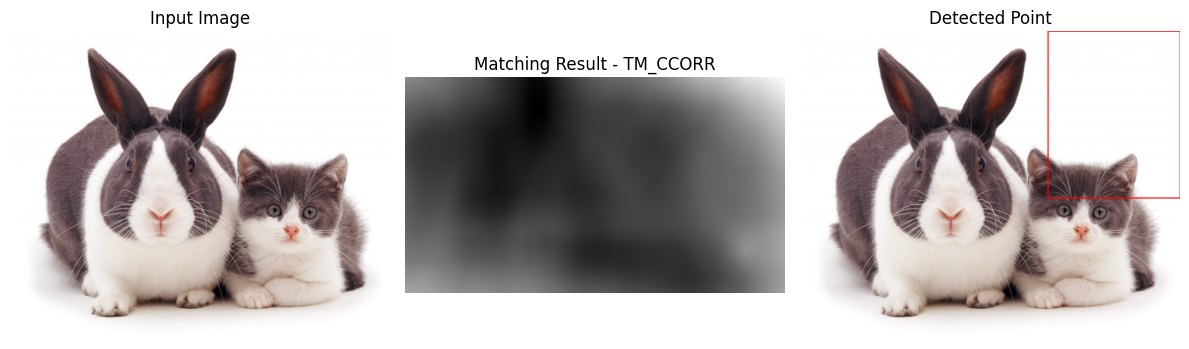

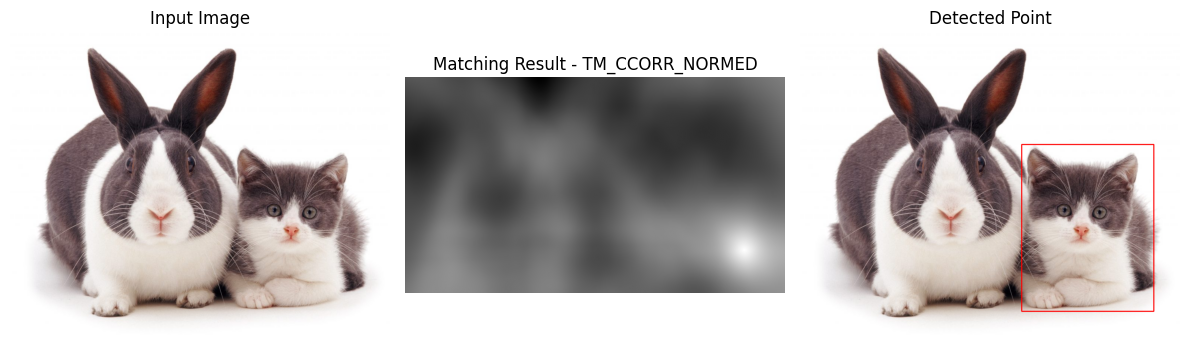

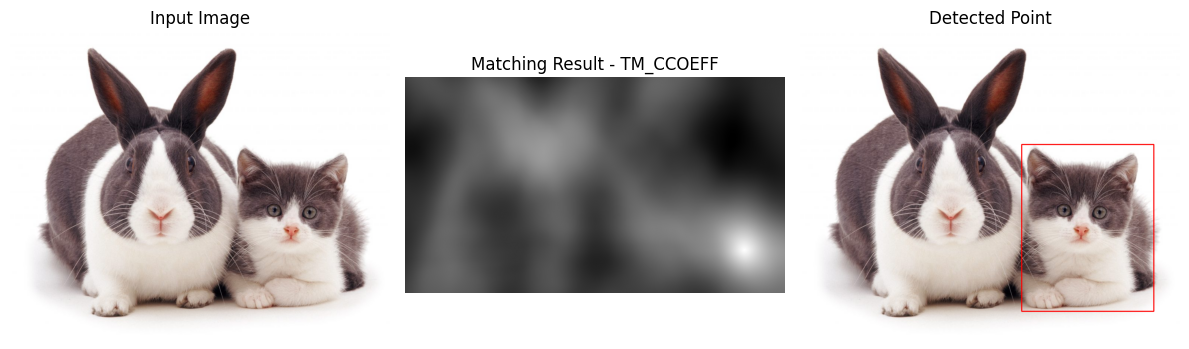

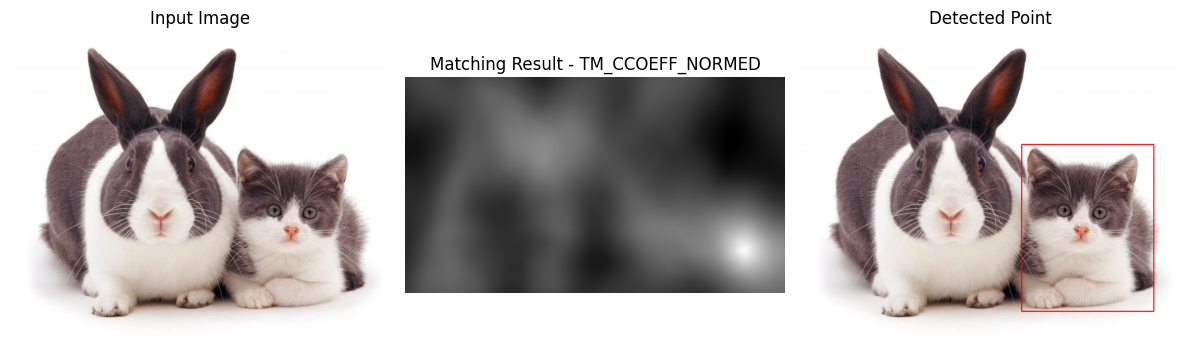

In [19]:
# Enam metode Template Matching pada OpenCV
methods = [
    ('TM_SQDIFF', cv2.TM_SQDIFF),
    ('TM_SQDIFF_NORMED', cv2.TM_SQDIFF_NORMED),
    ('TM_CCORR', cv2.TM_CCORR),
    ('TM_CCORR_NORMED', cv2.TM_CCORR_NORMED),
    ('TM_CCOEFF', cv2.TM_CCOEFF),
    ('TM_CCOEFF_NORMED', cv2.TM_CCOEFF_NORMED)
]

for method_name, method in methods:
    result = cv2.matchTemplate(source_gray, template_gray, method)
    min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(result)

    # SQDIFF mencari nilai minimum; metode lainnya mencari nilai maksimum
    top_left = min_loc if method in (cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED) else max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)

    detected = source.copy()
    cv2.rectangle(detected, top_left, bottom_right, (0, 0, 255), 2)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(source, cv2.COLOR_BGR2RGB))
    plt.title('Input Image')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(result, cmap='gray')
    plt.title('Matching Result - ' + method_name)
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(cv2.cvtColor(detected, cv2.COLOR_BGR2RGB))
    plt.title('Detected Point')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

Ukuran input: (586, 596)
Ukuran template: (73, 88)


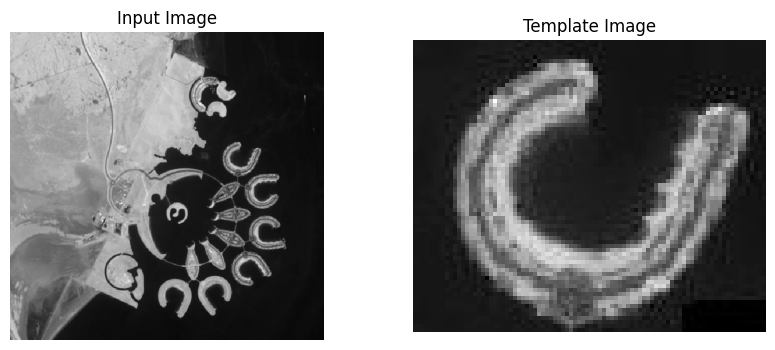

In [20]:
# Membaca gambar menggunakan PIL (tanpa fungsi pembacaan gambar OpenCV)
from PIL import Image
from skimage.feature import match_template

source_pil = Image.open(find_image('bahrain.jpg', [OBJECT_DIR])).convert('L')
template_pil = Image.open(find_image('bahrain-template.jpg', [OBJECT_DIR])).convert('L')

source_np = np.asarray(source_pil, dtype=np.float32)
template_np = np.asarray(template_pil, dtype=np.float32)

print('Ukuran input:', source_np.shape)
print('Ukuran template:', template_np.shape)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(source_np, cmap='gray'); plt.title('Input Image'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(template_np, cmap='gray'); plt.title('Template Image'); plt.axis('off')
plt.show()

Jumlah objek terdeteksi: 2


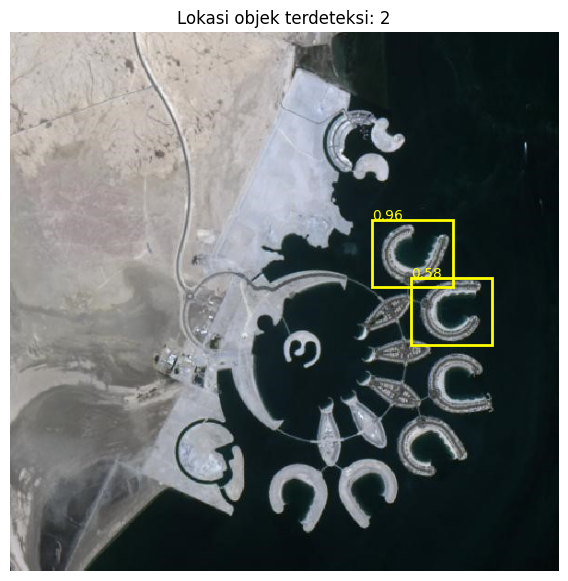

In [24]:
# Menghitung normalized cross-correlation dan mengambil beberapa lokasi terbaik
# skimage digunakan sebagai alternatif; OpenCV tidak digunakan pada proses matching.
matching_result = match_template(source_np, template_np, pad_input=False)

threshold = 0.55
candidate_y, candidate_x = np.where(matching_result >= threshold)
scores = matching_result[candidate_y, candidate_x]

# Urutkan kandidat dari skor tertinggi
order = np.argsort(scores)[::-1]
selected = []
template_h, template_w = template_np.shape

# Non-maximum suppression sederhana agar kotak tidak bertumpuk
for idx in order:
    x, y, score = int(candidate_x[idx]), int(candidate_y[idx]), float(scores[idx])
    if all(
        abs(x - sx) > template_w * 0.5 or abs(y - sy) > template_h * 0.5
        for sx, sy, _ in selected
    ):
        selected.append((x, y, score))

# Tampilkan hasil
result_rgb = np.array(Image.open(find_image('bahrain.jpg', [OBJECT_DIR])).convert('RGB')
)
for x, y, score in selected:
    plt_rect = (x, y, template_w, template_h)
    import matplotlib.patches as patches
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.imshow(result_rgb)
    for sx, sy, sc in selected:
        ax.add_patch(patches.Rectangle((sx, sy), template_w, template_h,
                                       linewidth=2, edgecolor='yellow', facecolor='none'))
        ax.text(sx, sy, f'{sc:.2f}', color='yellow')
    ax.set_title(f'Lokasi objek terdeteksi: {len(selected)}')
    ax.axis('off')
    break
if not selected:
    print('Tidak ada objek dengan threshold tersebut. Turunkan nilai threshold.')
else:
    print('Jumlah objek terdeteksi:', len(selected))
    plt.show()

Gambar yang digunakan: /content/drive/MyDrive/PCVK/Images/Object_Detection/car-park.jpg


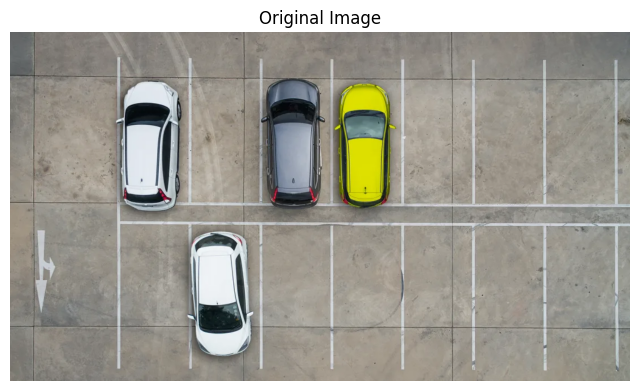

In [22]:
# Membaca gambar car-park
try:
    car_park_path = find_image('car-park.jpg', [OBJECT_DIR])
except FileNotFoundError:
    # Pada screenshot, nama file yang terlihat diawali "parking-lot-car..."
    car_park_path = find_image('parking-lot-car.jpg', [OBJECT_DIR])

car_park = cv2.imread(car_park_path)
print('Gambar yang digunakan:', car_park_path)
if car_park is None:
    raise ValueError('Gambar car-park.jpg tidak dapat dibaca.')

car_gray = cv2.cvtColor(car_park, cv2.COLOR_BGR2GRAY)
show_image(car_park, 'Original Image')

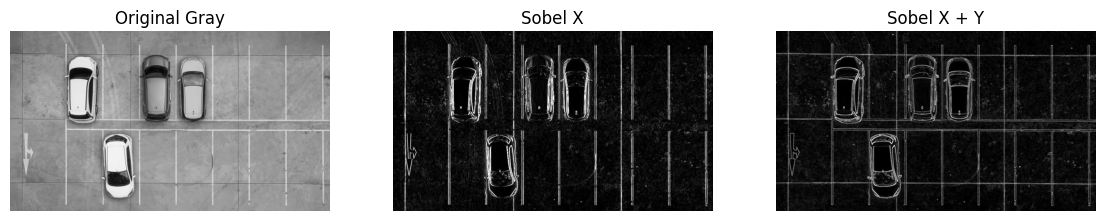

In [25]:
# a. Sobel Edge Detection
sobel_x = cv2.Sobel(car_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(car_gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)
sobel_combined = cv2.addWeighted(sobel_x_abs, 0.5, sobel_y_abs, 0.5, 0)

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1); plt.imshow(car_gray, cmap='gray'); plt.title('Original Gray'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(sobel_x_abs, cmap='gray'); plt.title('Sobel X'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(sobel_combined, cmap='gray'); plt.title('Sobel X + Y'); plt.axis('off')
plt.show()

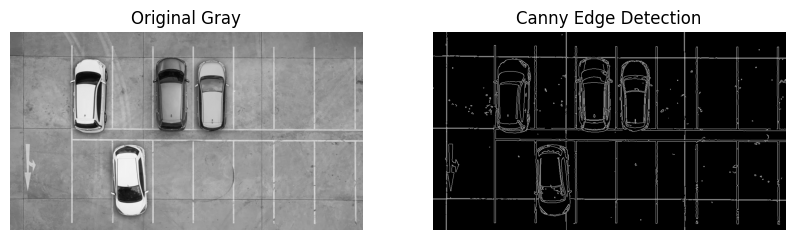

In [26]:
# b. Canny Edge Detection
canny_edges = cv2.Canny(car_gray, 100, 200)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(car_gray, cmap='gray'); plt.title('Original Gray'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(canny_edges, cmap='gray'); plt.title('Canny Edge Detection'); plt.axis('off')
plt.show()

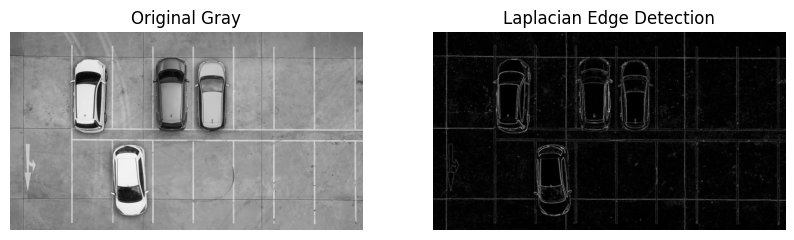

In [27]:
# c. Laplacian Edge Detection
laplacian = cv2.Laplacian(car_gray, cv2.CV_64F)
laplacian_abs = cv2.convertScaleAbs(laplacian)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(car_gray, cmap='gray'); plt.title('Original Gray'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(laplacian_abs, cmap='gray'); plt.title('Laplacian Edge Detection'); plt.axis('off')
plt.show()

### Soal 5 – Harris Corner Detection dan Shi-Tomasi Detection
Implementasikan metode Harris Corner Detection dan Shi-Tomasi Detection pada OpenCV menggunakan gambar `chess-board.jpg`.

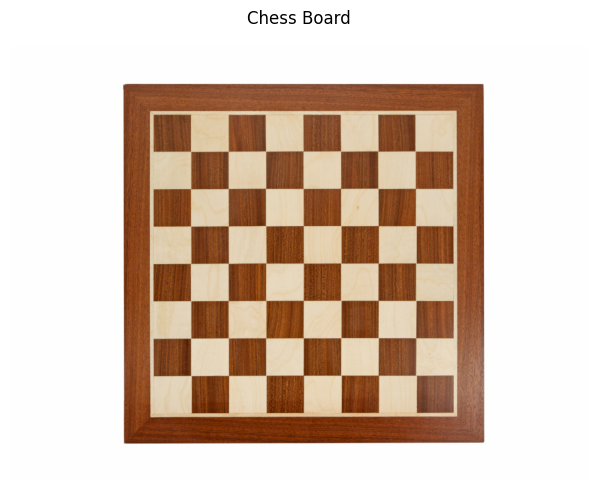

In [28]:
# Membaca gambar chess-board
chess = cv2.imread(image_path('chess-board.jpg', OBJECT_DIR))
if chess is None:
    raise ValueError('Gambar chess-board.jpg tidak dapat dibaca.')
chess_gray = cv2.cvtColor(chess, cv2.COLOR_BGR2GRAY)
show_image(chess, 'Chess Board')

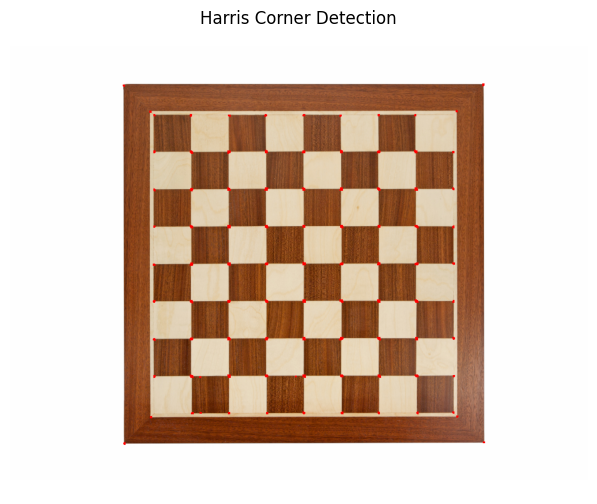

In [29]:
# a. Harris Corner Detection
harris_input = np.float32(chess_gray)
harris_response = cv2.cornerHarris(harris_input, blockSize=2, ksize=3, k=0.04)
harris_response = cv2.dilate(harris_response, None)

harris_output = chess.copy()
harris_output[harris_response > 0.01 * harris_response.max()] = [0, 0, 255]
show_image(harris_output, 'Harris Corner Detection')

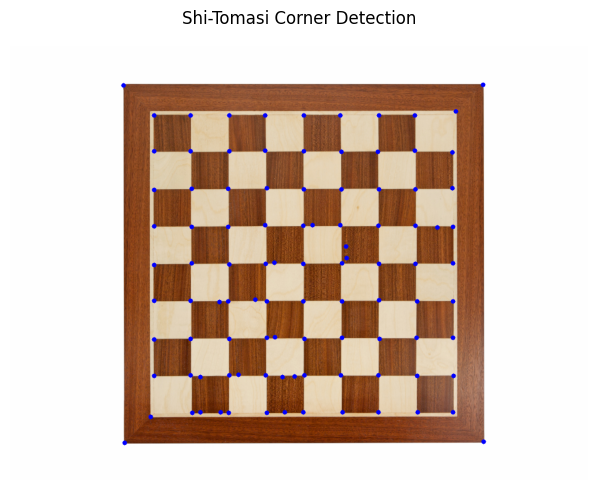

In [30]:
# b. Shi-Tomasi Corner Detection
shi_corners = cv2.goodFeaturesToTrack(
    chess_gray,
    maxCorners=100,
    qualityLevel=0.01,
    minDistance=10
)

shi_output = chess.copy()
if shi_corners is not None:
    shi_corners = np.int32(shi_corners)
    for corner in shi_corners:
        x, y = corner.ravel()
        cv2.circle(shi_output, (x, y), 4, (255, 0, 0), -1)

show_image(shi_output, 'Shi-Tomasi Corner Detection')

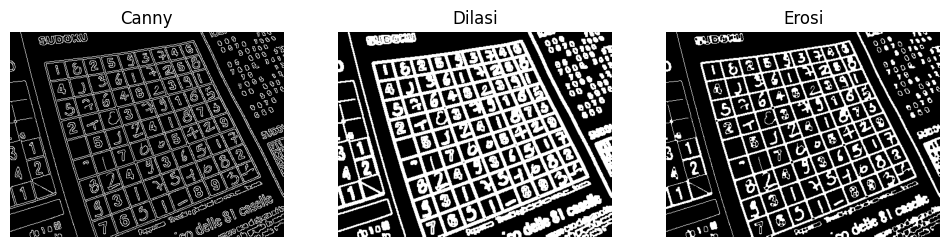

In [31]:
# Membaca gambar sudoku
sudoku = cv2.imread(image_path('sudoku.jpg', OBJECT_DIR))
if sudoku is None:
    raise ValueError('Gambar sudoku.jpg tidak dapat dibaca.')
sudoku_gray = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)

# Tahap 1: Canny Edge Detection
sudoku_edges = cv2.Canny(sudoku_gray, 50, 150)

# Tahap 2: Dilasi
kernel = np.ones((3, 3), np.uint8)
dilated = cv2.dilate(sudoku_edges, kernel, iterations=1)

# Tahap 3: Erosi
eroded = cv2.erode(dilated, kernel, iterations=1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(sudoku_edges, cmap='gray'); plt.title('Canny'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(dilated, cmap='gray'); plt.title('Dilasi'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(eroded, cmap='gray'); plt.title('Erosi'); plt.axis('off')
plt.show()

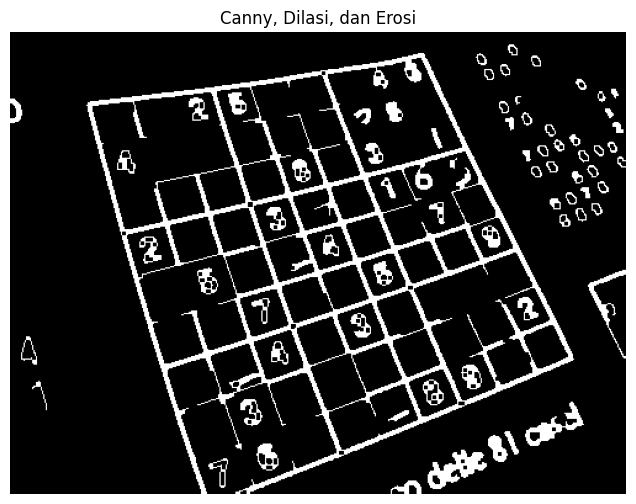

In [39]:
# Membaca gambar Sudoku
sudoku = cv2.imread(find_image('sudoku.jpg', [OBJECT_DIR]))

# Konversi ke grayscale
gray = cv2.cvtColor(sudoku, cv2.COLOR_BGR2GRAY)

# 1. Canny Edge Detection
edges = cv2.Canny(gray, 120, 250, apertureSize=3)

# 2. Dilasi
kernel = np.ones((3, 3), np.uint8)
edges = cv2.dilate(edges, kernel, iterations=1)

# 3. Erosi
edges = cv2.erode(edges, kernel, iterations=1)

show_image(edges, 'Canny, Dilasi, dan Erosi')

In [40]:
# 4. Hough Transform
lines = cv2.HoughLines(
    edges,
    1,
    np.pi / 180,
    180
)

print('Jumlah garis mentah:', 0 if lines is None else len(lines))

Jumlah garis mentah: 43


In [41]:
# 5. Merge Lines

def merge_lines(lines, rho_t=25, theta_t=np.pi / 36):

    merged = []

    if lines is None:
        return merged

    for line in lines:

        rho, theta = line[0]

        # Normalisasi rho agar positif
        if rho < 0:
            rho = -rho
            theta += np.pi

        found = False

        for group in merged:

            angle_diff = abs(theta - group[1])
            angle_diff = min(angle_diff, 2 * np.pi - angle_diff)

            if (
                abs(rho - group[0]) < rho_t
                and angle_diff < theta_t
            ):
                group[2].append((rho, theta))
                found = True
                break

        if not found:
            merged.append([rho, theta, [(rho, theta)]])

    # Rata-rata setiap kelompok garis
    result = []

    for group in merged:

        rho_avg = np.mean([item[0] for item in group[2]])

        # Rata-rata sudut menggunakan sin dan cos
        theta_avg = np.arctan2(
            np.mean([np.sin(item[1]) for item in group[2]]),
            np.mean([np.cos(item[1]) for item in group[2]])
        )

        result.append((rho_avg, theta_avg))

    return result


merged = merge_lines(lines)

print('Jumlah garis setelah digabung:', len(merged))

Jumlah garis setelah digabung: 14


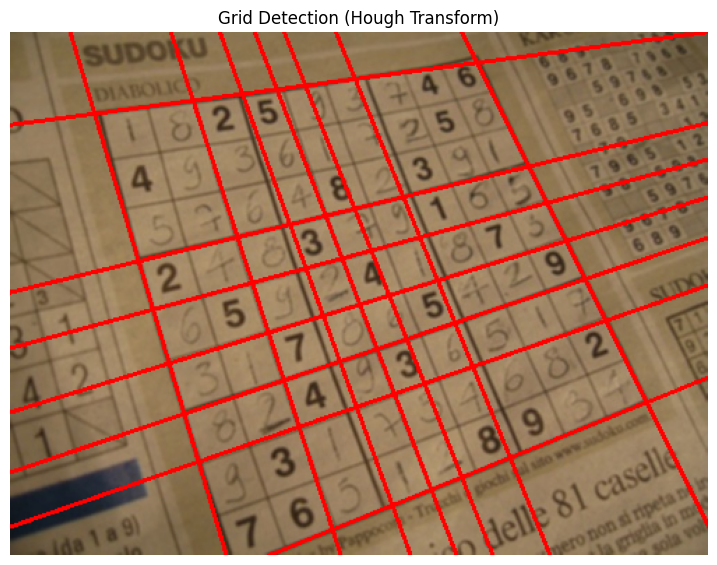

In [42]:
# 6. Menggambar garis hasil Hough Transform

out = sudoku.copy()

for rho, theta in merged:

    a = np.cos(theta)
    b = np.sin(theta)

    x0 = a * rho
    y0 = b * rho

    p1 = (
        int(x0 + 2000 * (-b)),
        int(y0 + 2000 * a)
    )

    p2 = (
        int(x0 - 2000 * (-b)),
        int(y0 - 2000 * a)
    )

    cv2.line(
        out,
        p1,
        p2,
        (0, 0, 255),
        2
    )

show_image(
    out,
    'Grid Detection (Hough Transform)',
    figsize=(9, 7)
)

Jumlah kontur: 3663


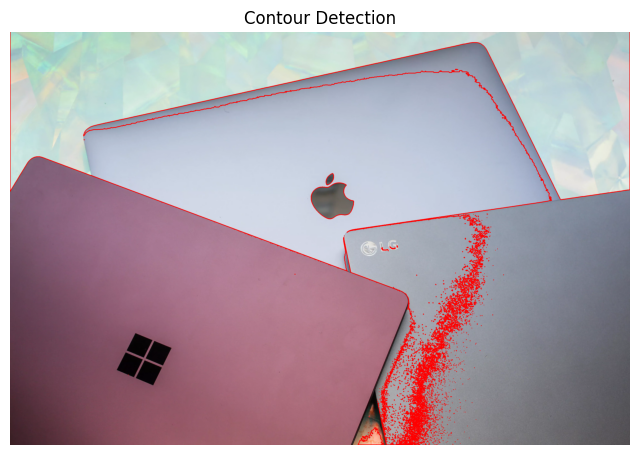

In [43]:
# Membaca gambar laptop
laptop = cv2.imread(image_path('laptop.jpg', OBJECT_DIR))
if laptop is None:
    raise ValueError('Gambar laptop.jpg tidak dapat dibaca.')

laptop_gray = cv2.cvtColor(laptop, cv2.COLOR_BGR2GRAY)
_, laptop_binary = cv2.threshold(
    laptop_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Menemukan kontur dan menggambarkannya
contours, hierarchy = cv2.findContours(
    laptop_binary,
    cv2.RETR_TREE,
    cv2.CHAIN_APPROX_SIMPLE
)

contour_output = laptop.copy()
cv2.drawContours(contour_output, contours, -1, (0, 0, 255), 3)

print('Jumlah kontur:', len(contours))
show_image(contour_output, 'Contour Detection')

Folder yang diproses: /content/drive/MyDrive/PCVK/Images/facedet
Jumlah gambar: 8
jokowi.jpg - wajah terdeteksi: 1


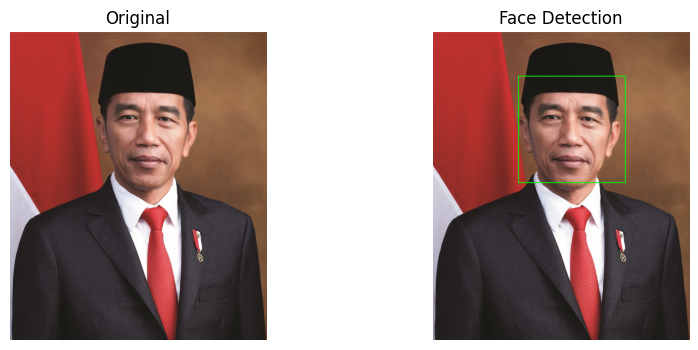

kartini.jpg - wajah terdeteksi: 1


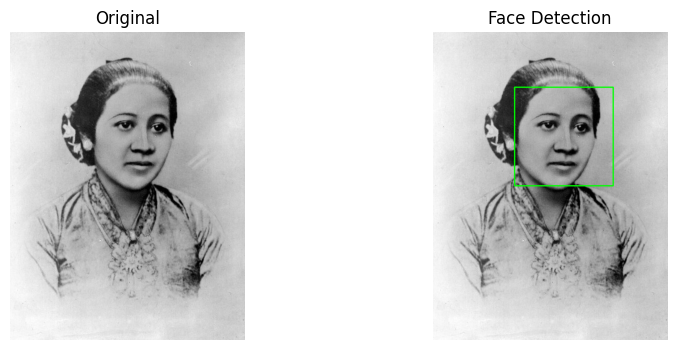

kucing.jpg - wajah terdeteksi: 0


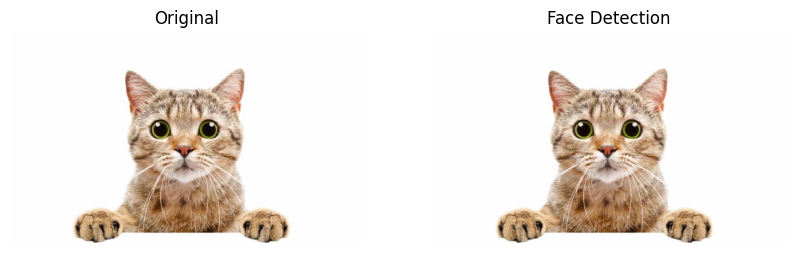

many_cereals.jpg - wajah terdeteksi: 0


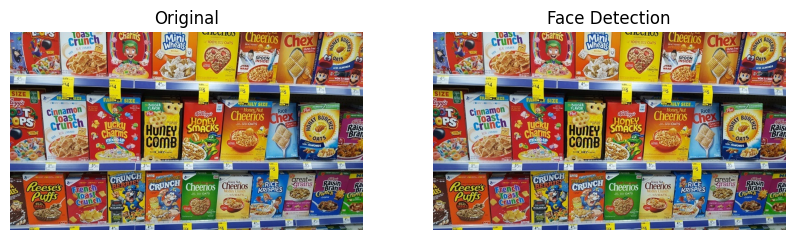

mask.png - wajah terdeteksi: 5


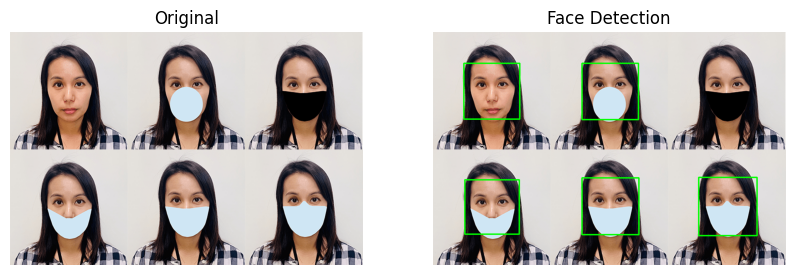

mjordan.jpg - wajah terdeteksi: 1


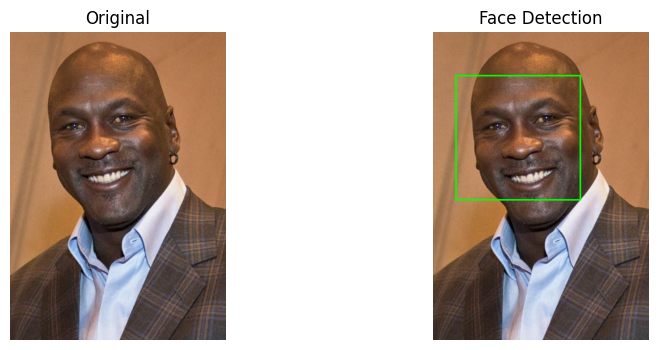

reeses_puffs.png - wajah terdeteksi: 0


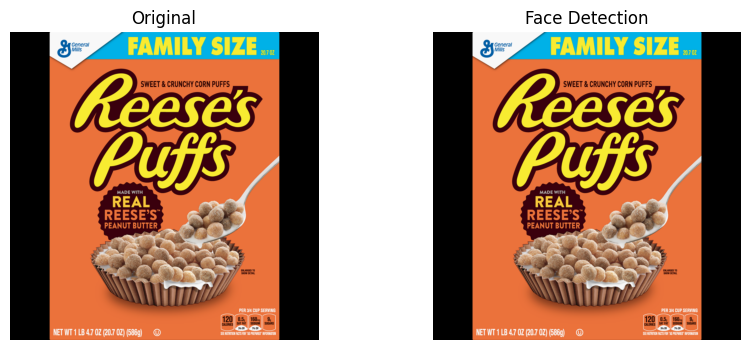

solvayconf.jpg - wajah terdeteksi: 27


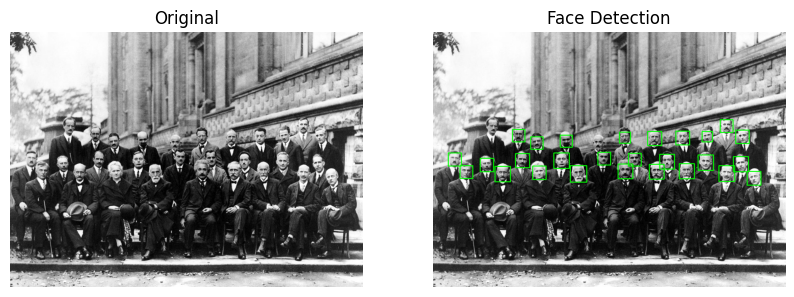

In [44]:
# Haar Cascade untuk deteksi wajah manusia
face_xml = os.path.join(HAAR_DIR, 'haarcascade_frontalface_alt.xml')
if not os.path.isfile(face_xml):
    face_xml = os.path.join(cv2.data.haarcascades, 'haarcascade_frontalface_default.xml')
face_cascade = cv2.CascadeClassifier(face_xml)
if face_cascade.empty():
    raise RuntimeError('File Haar Cascade wajah gagal dimuat.')

# Gunakan folder facedet jika tersedia; jika belum, gunakan gambar di Images
scan_dir = FACE_DIR
extensions = ('*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff')
face_files = []
for ext in extensions:
    face_files.extend(glob.glob(os.path.join(scan_dir, ext)))

print('Folder yang diproses:', scan_dir)
print('Jumlah gambar:', len(face_files))

for path in sorted(face_files):
    img = cv2.imread(path)
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(25, 25))
    output = img.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(output, (x, y), (x+w, y+h), (0, 255, 0), 2)
    print(os.path.basename(path), '- wajah terdeteksi:', len(faces))
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.title('Original'); plt.axis('off')
    plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB)); plt.title('Face Detection'); plt.axis('off')
    plt.show()

Gambar: /content/drive/MyDrive/PCVK/Images/Object_Detection/cat-and-rabbit.jpg
Wajah kucing terdeteksi: 0


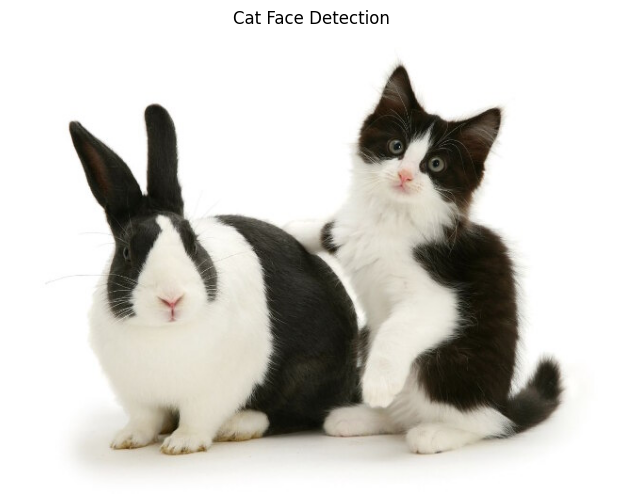

In [45]:
# Menggunakan Haar Cascade khusus wajah kucing
cat_cascade_candidates = [
    os.path.join(HAAR_DIR, 'haarcascade_frontalcatface_extended.xml'),
    os.path.join(HAAR_DIR, 'haarcascade_frontalcatface.xml'),
    os.path.join(cv2.data.haarcascades, 'haarcascade_frontalcatface_extended.xml'),
    os.path.join(cv2.data.haarcascades, 'haarcascade_frontalcatface.xml')
]
cat_cascade_path = next((p for p in cat_cascade_candidates if os.path.isfile(p)), None)
if cat_cascade_path is None:
    raise FileNotFoundError('XML Haar Cascade wajah kucing tidak ditemukan di Images/haarcascades maupun OpenCV.')

cat_cascade = cv2.CascadeClassifier(cat_cascade_path)
if cat_cascade.empty():
    raise RuntimeError('Cascade wajah kucing gagal dimuat.')

# Gambar kucing pada folder Object_Detection (nama pada screenshot diawali cat-and-rabbit)
cat_img_path = find_image('cat-and-rabbit.jpg', [OBJECT_DIR])
cat_img = cv2.imread(cat_img_path)
if cat_img is None:
    raise ValueError(f'Gambar tidak dapat dibaca: {cat_img_path}')

cat_gray = cv2.cvtColor(cat_img, cv2.COLOR_BGR2GRAY)
cat_faces = cat_cascade.detectMultiScale(
    cat_gray, scaleFactor=1.05, minNeighbors=3, minSize=(40, 40)
)

cat_output = cat_img.copy()
for (x, y, w, h) in cat_faces:
    cv2.rectangle(cat_output, (x, y), (x+w, y+h), (255, 255, 255), 2)

print('Gambar:', cat_img_path)
print('Wajah kucing terdeteksi:', len(cat_faces))
show_image(cat_output, 'Cat Face Detection')

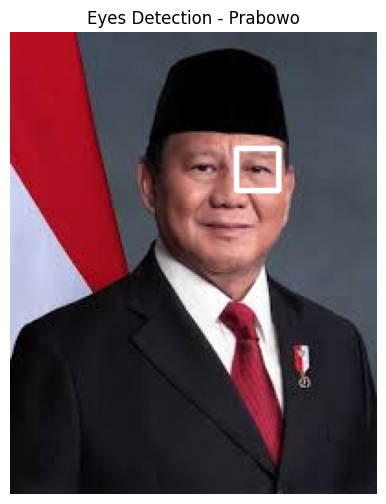

In [46]:
# Membaca gambar Pak Prabowo
prabowo = cv2.imread(find_image('prabowo.jpg', [FACE_DIR, IMAGE_DIR]))
if prabowo is None:
    raise ValueError('Gambar prabowo.jpg tidak dapat dibaca.')

prabowo_gray = cv2.cvtColor(prabowo, cv2.COLOR_BGR2GRAY)

# Deteksi wajah terlebih dahulu
face = face_cascade.detectMultiScale(prabowo_gray, 1.1, 5, minSize=(50, 50))

# Haar Cascade untuk mata
eye_xml = os.path.join(HAAR_DIR, 'haarcascade_eye.xml')
if not os.path.isfile(eye_xml):
    eye_xml = os.path.join(cv2.data.haarcascades, 'haarcascade_eye.xml')
eye_cascade = cv2.CascadeClassifier(eye_xml)
prabowo_output = prabowo.copy()

for (x, y, w, h) in face:
    roi_gray = prabowo_gray[y:y+h, x:x+w]
    roi_color = prabowo_output[y:y+h, x:x+w]
    eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.1, minNeighbors=5)
    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(roi_color, (ex, ey), (ex+ew, ey+eh), (255, 255, 255), 2)

show_image(prabowo_output, 'Eyes Detection - Prabowo')

In [51]:
# Membaca gambar people
people = cv2.imread(find_image('people.png', [FACE_DIR, IMAGE_DIR]))

if people is None:
    raise ValueError('Gambar people.png tidak dapat dibaca.')

# Konversi ke grayscale
people_gray = cv2.cvtColor(people, cv2.COLOR_BGR2GRAY)

# Meningkatkan kontras gambar
people_gray = cv2.equalizeHist(people_gray)

# Haar Cascade untuk wajah
face_xml = os.path.join(HAAR_DIR, 'haarcascade_frontalface_default.xml')

if not os.path.isfile(face_xml):
    face_xml = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'

face_cascade = cv2.CascadeClassifier(face_xml)

# Haar Cascade untuk senyuman
smile_xml = os.path.join(HAAR_DIR, 'haarcascade_smile.xml')

if not os.path.isfile(smile_xml):
    smile_xml = cv2.data.haarcascades + 'haarcascade_smile.xml'

smile_cascade = cv2.CascadeClassifier(smile_xml)

In [52]:
# Deteksi wajah
faces = face_cascade.detectMultiScale(
    people_gray,
    scaleFactor=1.1,
    minNeighbors=4,
    minSize=(25, 25)
)

people_output = people.copy()

total_smiles = 0

for (x, y, w, h) in faces:

    # Mengambil area wajah
    face_roi = people_gray[y:y+h, x:x+w]

    # Fokus pada bagian bawah wajah (mulut)
    mouth_y = int(h * 0.45)
    mouth_roi = face_roi[mouth_y:h, :]

    # Deteksi senyuman
    smiles = smile_cascade.detectMultiScale(
        mouth_roi,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(12, 8)
    )

    # Menggambar rectangle pada senyuman
    for (sx, sy, sw, sh) in smiles:

        cv2.rectangle(
            people_output,
            (x + sx, y + mouth_y + sy),
            (x + sx + sw, y + mouth_y + sy + sh),
            (0, 255, 0),
            2
        )

        total_smiles += 1

print('Jumlah wajah terdeteksi:', len(faces))
print('Senyuman terdeteksi:', total_smiles)

Jumlah wajah terdeteksi: 9
Senyuman terdeteksi: 3


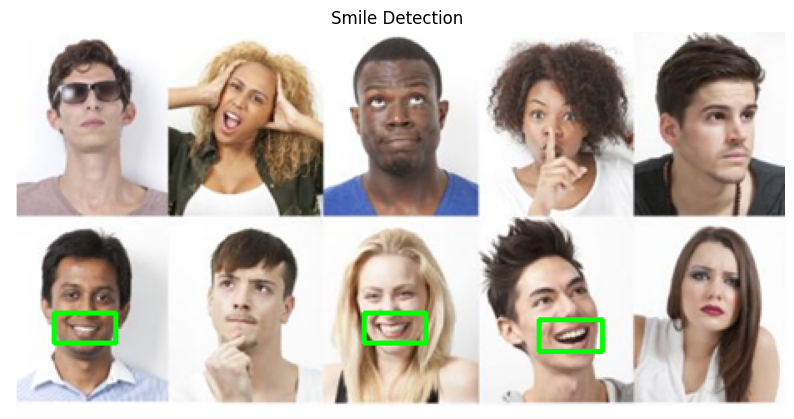

In [53]:
show_image(
    people_output,
    'Smile Detection',
    figsize=(10, 7)
)


In [ ]:
import io
import cv2 as cv
import numpy as np
import PIL.Image
from base64 import b64decode, b64encode
from IPython.display import display, Javascript
from google.colab.output import eval_js

def js_to_image(js_reply):
    image_bytes = b64decode(js_reply.split(',')[1])
    jpg_as_np = np.frombuffer(image_bytes, dtype=np.uint8)
    img = cv.imdecode(jpg_as_np, flags=1)
    return img

def bbox_to_bytes(bbox_array):
    bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')
    iobuf = io.BytesIO()
    bbox_PIL.save(iobuf, format='png')
    bbox_bytes = 'data:image/png;base64,{}'.format((str(b64encode(iobuf.getvalue()), 'utf-8')))
    return bbox_bytes

def video_stream():
    js = Javascript('''
        var video;
        var div = null;
        var stream;
        var captureCanvas;
        var imgElement;
        var labelElement;
        var pendingResolve = null;
        var shutdown = false;

        function removeDom() {
           stream.getVideoTracks()[0].stop();
           video.remove();
           div.remove();
           video = null;
           div = null;
           stream = null;
           imgElement = null;
           captureCanvas = null;
           labelElement = null;
        }

        function onAnimationFrame() {
          if (!shutdown) {
            window.requestAnimationFrame(onAnimationFrame);
          }
          if (pendingResolve) {
            var result = "";
            if (!shutdown) {
              captureCanvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
              result = captureCanvas.toDataURL('image/jpeg', 0.8)
            }
            var lp = pendingResolve;
            pendingResolve = null;
            lp(result);
          }
        }

        async function createDom() {
          if (div !== null) {
            return stream;
          }
          div = document.createElement('div');
          div.style.border = '2px solid black';
          div.style.padding = '3px';
          div.style.width = '100%';
          div.style.maxWidth = '600px';
          document.body.appendChild(div);

          const modelOut = document.createElement('div');
          modelOut.innerHTML = "<span>Status: </span>";
          labelElement = document.createElement('span');
          labelElement.innerText = 'No data';
          labelElement.style.fontWeight = 'bold';
          modelOut.appendChild(labelElement);
          div.appendChild(modelOut);

          video = document.createElement('video');
          video.style.display = 'block';
          video.width = div.clientWidth - 6;
          video.setAttribute('playsinline', '');
          video.onclick = () => { shutdown = true; };
          stream = await navigator.mediaDevices.getUserMedia(
              {video: { facingMode: "environment"}});
          div.appendChild(video);

          imgElement = document.createElement('img');
          imgElement.style.position = 'absolute';
          imgElement.style.zIndex = 1;
          imgElement.onclick = () => { shutdown = true; };
          div.appendChild(imgElement);

          const instruction = document.createElement('div');
          instruction.innerHTML =
              '<span style="color: red; font-weight: bold;">' +
              'Klik video untuk menghentikan kamera</span>';
          div.appendChild(instruction);
          instruction.onclick = () => { shutdown = true; };

          video.srcObject = stream;
          await video.play();

          captureCanvas = document.createElement('canvas');
          captureCanvas.width = 640;
          captureCanvas.height = 480;
          window.requestAnimationFrame(onAnimationFrame);
          return stream;
        }
        async function stream_frame(label, imgData) {
          if (shutdown) {
            removeDom();
            shutdown = false;
            return '';
          }
          var preCreate = Date.now();
          stream = await createDom();
          var preShow = Date.now();
          if (label != "") {
            labelElement.innerHTML = label;
          }
          if (imgData != "") {
            var videoRect = video.getClientRects()[0];
            imgElement.style.top = videoRect.top + "px";
            imgElement.style.left = videoRect.left + "px";
            imgElement.style.width = videoRect.width + "px";
            imgElement.style.height = videoRect.height + "px";
            imgElement.src = imgData;
          }
          var preCapture = Date.now();
          var result = await new Promise(function(resolve, reject) {
            pendingResolve = resolve;
          });
          shutdown = false;
          return {'create': preShow - preCreate,
                  'show': preCapture - preShow,
                  'capture': Date.now() - preCapture,
                  'img': result};
        }
        ''')
    display(js)

def video_frame(label, bbox):
    data = eval_js('stream_frame("{}", "{}")'.format(label, bbox))
    return data

face_cascade = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')

try:
    video_stream()
    label_html = 'Capturing...'
    bbox = ''
    while True:
        js_reply = video_frame(label_html, bbox)
        if not js_reply:
            break
        img = js_to_image(js_reply["img"])
        bbox_array = np.zeros([480, 640, 4], dtype=np.uint8)
        gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray)
        for (x, y, w, h) in faces:
            bbox_array = cv.rectangle(bbox_array, (x, y), (x + w, y + h), (255, 0, 0), 2)
        bbox_array[:, :, 3] = (bbox_array.max(axis=2) > 0).astype(int) * 255
        bbox = bbox_to_bytes(bbox_array)
except Exception as e:
    print("Kamera tidak aktif / dihentikan:", e)

<IPython.core.display.Javascript object>

/tmp/ipykernel_415/11637206.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  bbox_PIL = PIL.Image.fromarray(bbox_array, 'RGBA')


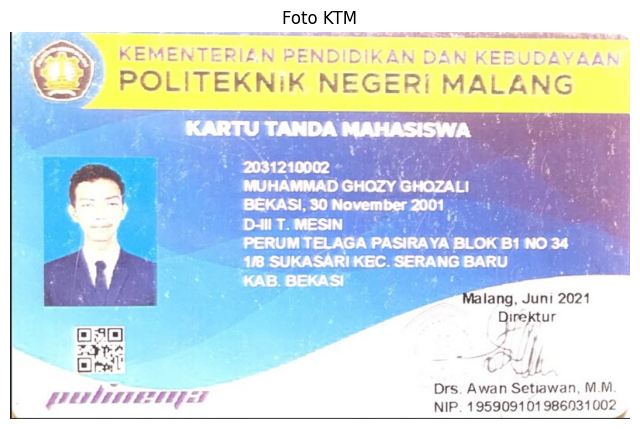

In [70]:
# a-b. Membaca dan menampilkan gambar KTM
ktm = cv2.imread(image_path('KTM lama.jpg'))
if ktm is None:
    raise ValueError('File KTM lama.jpg tidak dapat dibaca.')

show_image(ktm, 'Foto KTM')

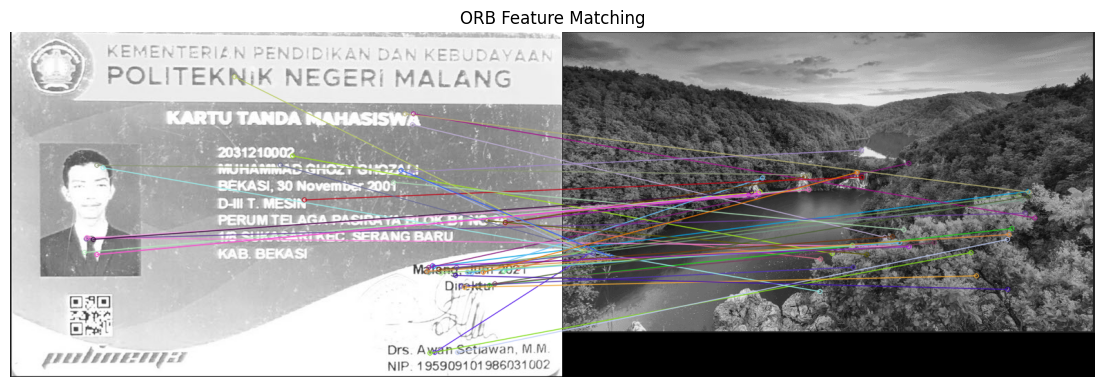

Jumlah pasangan fitur yang cocok: 339


In [72]:
# c. Feature Matching menggunakan ORB dan Brute-Force Matcher
# Gambar pertama: KTM sebagai template
# Gambar kedua: KTM bersama barang lain
ktm_template = cv2.imread(image_path('KTM lama.jpg'), cv2.IMREAD_GRAYSCALE)
ktm_scene = cv2.imread(find_image('jungle.jpg', [IMAGE_DIR]), cv2.IMREAD_GRAYSCALE)

if ktm_template is None or ktm_scene is None:
    raise ValueError('Pastikan KTM lama.jpg dan ktm_dengan_barang.jpg tersedia.')

orb = cv2.ORB_create(nfeatures=1500)
keypoints1, descriptors1 = orb.detectAndCompute(ktm_template, None)
keypoints2, descriptors2 = orb.detectAndCompute(ktm_scene, None)

if descriptors1 is None or descriptors2 is None:
    raise ValueError('Fitur ORB tidak berhasil ditemukan pada salah satu gambar.')

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(descriptors1, descriptors2)
matches = sorted(matches, key=lambda x: x.distance)

matching_result = cv2.drawMatches(
    ktm_template, keypoints1,
    ktm_scene, keypoints2,
    matches[:50], None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

show_image(matching_result, 'ORB Feature Matching', figsize=(14, 7))
print('Jumlah pasangan fitur yang cocok:', len(matches))